# Lesson 17 - EfficientNet-B0 with the engineered features

Lesson 16 reached 78.9 % per ship with gradient boosting on the engineered numbers (five classes: cargo and
tanker merged). Does a CNN that also **looks at the spectrogram** do better? And does the CNN need the
high-frequency bins of the spectrogram, which look almost the same for every class?

One network, fed with both:

```
mel spectrogram (1 x bands x 501) -> EfficientNet-B0 (ImageNet start) -> 1280 numbers -+
                                                                                        +-> 5 classes
139 engineered numbers (lesson 15's best set) -> 128 numbers -------------------------+
```

- The 139 engineered numbers are all groups except "loudness and impulsiveness" (lesson 15).
- Two versions: all 128 mel bands (10 Hz - 16 kHz), and only the 101 bands below 8 kHz.
- Five classes, lesson 13's folds, test ships and ship weights; fold 1 first, all five folds in section 3. The epoch kept is the one with
  the best balanced accuracy on the validation fold; the test fold is scored per clip and per ship (lesson 16).
- For a fair reference, gradient boosting and logistic regression are trained on the same 139 numbers, same fold.

```
python src/fusion_cnn.py --top-hz 16000    # GPU, about 15 minutes on an RTX 3050 Laptop
python src/fusion_cnn.py --top-hz 8000
python src/fusion_cnn.py --reference       # CPU, a few minutes
```

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix
import five_classes as F5
import fusion_cnn as FC

OUT = FC.OUT_DIR
runs = {"EfficientNet-B0 + features, 128 bands (to 16 kHz)": "f1_16k",
        "EfficientNet-B0 + features, 101 bands (to 8 kHz)": "f1_8k"}
res = {name: json.loads((OUT / d / "results.json").read_text()) for name, d in runs.items()}
for r in json.loads((OUT / "reference_f1.json").read_text()):
    res[f"{r['model']}, same 139 numbers"] = r
pd.set_option("display.width", 160)

D:\shipsound\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Training

Balanced accuracy on the validation fold after each pass over the training data (the training loss keeps falling):

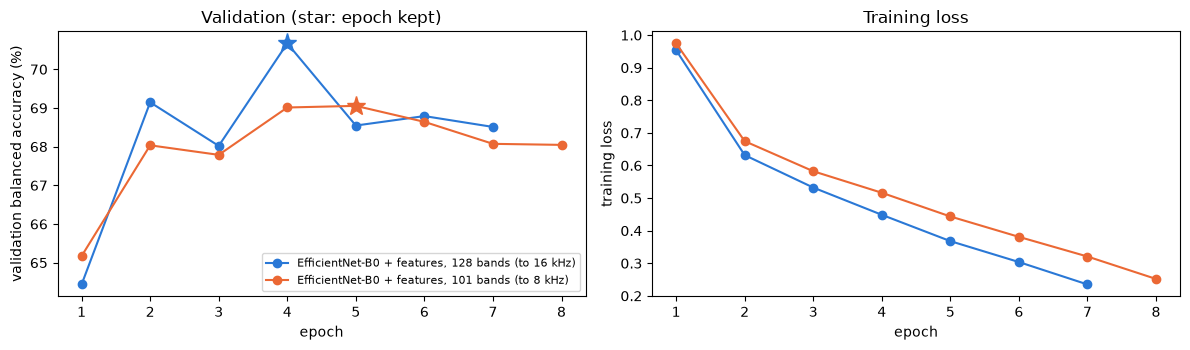

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for (name, d), color in zip(runs.items(), ["#2a78d6", "#eb6834"]):
    log = pd.read_csv(OUT / d / "log.csv")
    ax[0].plot(log.epoch, 100 * log.val_balanced_accuracy, "o-", color=color, label=name)
    ax[1].plot(log.epoch, log.train_loss, "o-", color=color)
    best = res[name]["best_epoch"]
    ax[0].plot(best, 100 * log.val_balanced_accuracy[log.epoch == best].iloc[0], "*", ms=14, color=color)
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("validation balanced accuracy (%)"); ax[0].legend(fontsize=8)
ax[0].set_title("Validation (star: epoch kept)")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("training loss"); ax[1].set_title("Training loss")
plt.tight_layout(); plt.show()

The best epoch comes early (4-5), then validation stops improving while the training loss keeps falling: the
network starts to memorise the training ships, as the CNNs of lessons 05-07 did.

## 2. Results on the test fold

                                                   per clip (%)  per ship (%)  recall background (%)  recall cargo + tanker (%)  recall fishing (%)  recall pleasurecraft (%)  recall tug (%)
EfficientNet-B0 + features, 128 bands (to 16 kHz)          69.8          77.6                   86.5                       95.9                43.5                      61.6            61.5
EfficientNet-B0 + features, 101 bands (to 8 kHz)           68.6          75.8                   78.8                       95.3                45.1                      66.7            57.4
logistic regression, same 139 numbers                      70.9          77.9                   85.7                       96.1                48.9                      64.5            59.4
gradient boosting, same 139 numbers                        71.1          80.6                   88.0                       95.8                48.0                      64.3            59.3


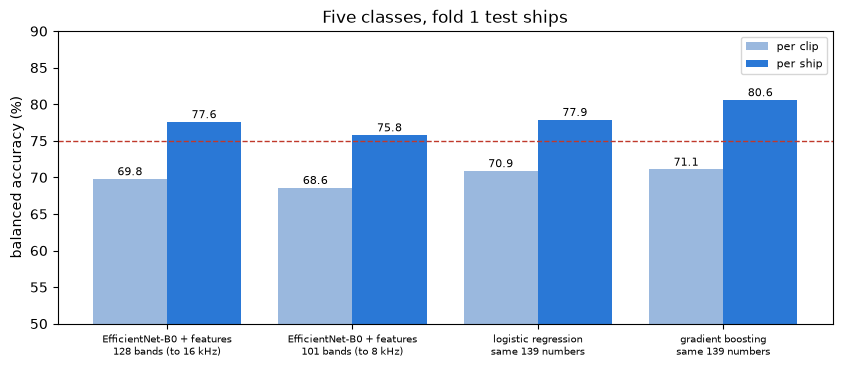

In [3]:
table = pd.DataFrame({name: {"per clip (%)": 100 * r["balanced_accuracy"],
                             "per ship (%)": 100 * r["per_ship_balanced_accuracy"],
                             **{f"recall {c} (%)": 100 * v for c, v in r["per_class_recall"].items()}}
                      for name, r in res.items()}).T.round(1)
print(table.to_string())

fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(table))
ax.bar(x - 0.2, table["per clip (%)"], 0.4, color="#9ab8de", label="per clip")
ax.bar(x + 0.2, table["per ship (%)"], 0.4, color="#2a78d6", label="per ship")
for i, (c, s) in enumerate(zip(table["per clip (%)"], table["per ship (%)"])):
    ax.text(i - 0.2, c + 0.5, f"{c:.1f}", ha="center", fontsize=8); ax.text(i + 0.2, s + 0.5, f"{s:.1f}", ha="center", fontsize=8)
ax.axhline(75, color="#c0392b", ls="--", lw=1)
ax.set_xticks(x, [n.replace(", ", "\n", 1) for n in table.index], fontsize=7)
ax.set_ylim(50, 90); ax.set_ylabel("balanced accuracy (%)"); ax.legend(fontsize=8)
ax.set_title("Five classes, fold 1 test ships"); plt.show()

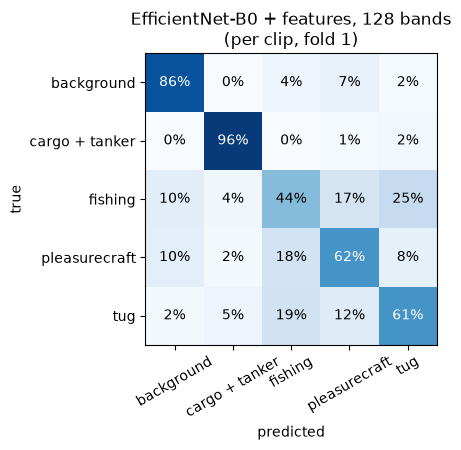

In [4]:
p = pd.read_parquet(OUT / "f1_16k" / "predictions.parquet")
cm = confusion_matrix(p.y, p[[f"p_{c}" for c in F5.CLASSES5]].to_numpy().argmax(1), normalize="true")
fig, ax = plt.subplots(figsize=(5.5, 4.6))
ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{cm[i, j]:.0%}", ha="center", va="center", color="white" if cm[i, j] > 0.5 else "black")
ax.set_xticks(range(5), F5.CLASSES5, rotation=30); ax.set_yticks(range(5), F5.CLASSES5)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title("EfficientNet-B0 + features, 128 bands\n(per clip, fold 1)"); plt.tight_layout(); plt.show()

## 3. All five folds (128 bands)

The same network on every fold, each with its gradient-boosting and logistic-regression reference on the same 139
numbers:

In [5]:
rows = []
for k in range(1, 6):
    r = json.loads((OUT / f"f{k}_16k" / "results.json").read_text())
    rows.append({"fold": k, "model": "EfficientNet-B0 + features", "per clip": r["balanced_accuracy"],
                 "per ship": r["per_ship_balanced_accuracy"]})
    for g in json.loads((OUT / f"reference_f{k}.json").read_text()):
        rows.append({"fold": k, "model": g["model"], "per clip": g["balanced_accuracy"],
                     "per ship": g["per_ship_balanced_accuracy"]})
folds5 = pd.DataFrame(rows)
print((100 * folds5.pivot(index="fold", columns="model", values="per ship")).round(1))
summary5 = folds5.groupby("model")[["per clip", "per ship"]].agg(["mean", "std"])
print((100 * summary5).round(1))

model  EfficientNet-B0 + features  gradient boosting  logistic regression
fold                                                                     
1                            77.6               80.6                 77.9
2                            76.4               75.5                 74.5
3                            76.2               78.8                 76.5
4                            77.6               81.6                 78.2
5                            74.0               78.2                 73.6
                           per clip      per ship     
                               mean  std     mean  std
model                                                 
EfficientNet-B0 + features     69.0  1.6     76.4  1.5
gradient boosting              69.9  1.7     78.9  2.4
logistic regression            68.6  1.9     76.1  2.0


## 4. What it means

| Five classes, fold 1 test ships | Per clip | Per ship |
|---|---|---|
| EfficientNet-B0 + 139 features, 128 bands (to 16 kHz) | 69.8 % | 77.6 % |
| EfficientNet-B0 + 139 features, 101 bands (to 8 kHz) | 68.6 % | 75.8 % |
| logistic regression, same 139 numbers | 70.9 % | 77.9 % |
| **gradient boosting, same 139 numbers** | **71.1 %** | **80.6 %** |

| Five classes, all 5 test folds (mean ± spread) | Per clip | Per ship |
|---|---|---|
| EfficientNet-B0 + 139 features | 69.0 ± 1.6 % | 76.4 ± 1.5 % |
| logistic regression, same 139 numbers | 68.6 ± 1.9 % | 76.1 ± 2.0 % |
| **gradient boosting, same 139 numbers** | **69.9 ± 1.7 %** | **78.9 ± 2.4 %** |

- **The CNN doesn't beat gradient boosting** on the same engineered numbers: 1.3 points lower per clip and 3.0
  per ship. Looking at the spectrogram as an image adds nothing that the 139 numbers don't already carry, and the
  CNN starts memorising the training ships after 4-5 epochs.
- **The CNN also needs the high frequencies:** without the bands above 8 kHz it loses 1.2 points per clip and 1.8
  per ship, as the classical models did in lesson 15. Background suffers most (86.5 → 78.8 % recall).
- **Cost:** about 15 minutes on the GPU per run, against about 1 minute on the CPU for gradient boosting.
- **All five folds confirm it:** gradient boosting is ahead per ship on 4 of 5 folds (78.9 against 76.4 % on
  average); the CNN wins only fold 2 (76.4 against 75.5 %).
- **Recommendation:** gradient boosting on the 139 engineered numbers stays the model to report.